# Decomposing coherent-GGI change into female and male adoption

The coherent GGI is a ratio, so its log change splits **exactly** into a female and a male term:

```
GGI_ct           = female_ct / male_ct
delta_log_GGI    = log(GGI_c,t1)    - log(GGI_c,t0)
female_component = log(female_c,t1) - log(female_c,t0)
male_component   = -[log(male_c,t1) - log(male_c,t0)]

delta_log_GGI    = female_component + male_component        (identity)
```

The point of the exercise is that a **narrowing gap is not the same thing as women gaining access**.
The gap also narrows when men lose access, or when both sexes lose access and men lose more. Those
are parity improvements without access expansion, and they are labelled as such everywhere below —
never as improved digital access.

Every table is built by `src/ggi_decomposition.py`, for **both** indicators; this notebook only
plots. **`INDICATOR` at the top of the setup cell chooses which one is displayed** — every figure
and table below is built for that indicator alone, and figures carry it in their filename, so
switching and rerunning accumulates both sets rather than overwriting one with the other.
The generated summary at the end is the one exception: it still covers both, because `doc/` is a
repo artefact and halving it would be a regression.

Primary interval **2015–2025**, with 2015–2020, 2020–2025 and all consecutive annual pairs also
computed. 2026 is excluded as a partial year (D18).

**Parity is the ceiling** (`params.level_ceiling_ctrl`). Where women's predicted adoption exceeds
men's there is no gap against women, so movement above parity must not read as a widening gap. The
cap is applied to the **female level** (`female* = min(female, male)`), which gives the same series
as capping the GGI at 1 but keeps `GGI* = female*/male` a genuine ratio — so the identity above
still holds exactly. Capping the ratio directly would break it. Rows where the cap binds are
flagged `ceiling_binding`; there the female component measures change in `min(female, male)` rather
than in female adoption alone (D25).

Countries **already at or above parity at both endpoints** are separated into their own category
(**8**) rather than dropped. There was no gap against women to close, so their near-zero change is a
standing state, not a negligible movement — but they stay in the denominator, because dropping them
would remove countries non-randomly by region and income. A country that *crosses into* parity
during the window is **not** in category 8: its convergence is the finding, and it keeps its
convergence category (D26).

In [1]:
import sys
from pathlib import Path

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))
import re
import warnings

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ggi_decomposition
import params

NOTEBOOK = '06_coherent_ggi_decomposition'
import utils

warnings.filterwarnings('ignore')

STYLE = params.STYLE
PALETTE = STYLE['colors']
INK, MUTED, GRID = '#222222', '#666666', '#d9d9d9'
FIGDIR = params.fig_dir(NOTEBOOK)
FIGDIR.mkdir(parents=True, exist_ok=True)

PRIMARY = '2015-2025'

# ====================================================================================================
# which indicator this run displays
# ====================================================================================================
# One indicator per run. Set it here and rerun the notebook; nothing else needs touching. The two
# indicators want different treatment rather than a shared panel — internet occupies only three of
# the eight categories, so a two-indicator legend advertises classes that are empty for one of them.
INDICATOR = 'mobile'            # 'mobile' | 'internet'
assert INDICATOR in params.COHERENT_GGI['indicators'], f'unknown indicator: {INDICATOR}'


def latest(stem):
    matches = sorted(f for f in params.table_dir(NOTEBOOK).glob(f'ggi_decomposition_{stem}_*.csv')
                     if re.fullmatch(rf'ggi_decomposition_{stem}_\d{{8}}\.csv', f.name))
    if not matches:
        raise FileNotFoundError(f'no ggi_decomposition_{stem}_<date>.csv — run src/ggi_decomposition.py')
    return pd.read_csv(matches[-1])


codebook   = latest('codebook')
country    = latest('country_period')
exclusions = latest('exclusions')
sens       = latest('sensitivity')
identity   = latest('identity_check')
cat_global = latest('category_global')
cat_region = latest('category_regional')
extremes   = latest('extremes')
regional   = latest('regional_aggregate')

CATS = codebook.sort_values('code')
CAT_LABEL = dict(zip(CATS['code'], CATS['label']))
NO_ACCESS_GAIN = {3, 4}


def sel(df):
    """restrict an indicator-grained table to the one being displayed; pass anything else through"""
    return df[df['indicator'] == INDICATOR] if 'indicator' in df.columns else df


def at(df, interval=PRIMARY):
    """the displayed indicator, at one interval"""
    d = sel(df)
    return d[d['interval'] == interval]

# Seven categories cannot be told apart by hue alone: at seven simultaneous series no palette clears
# the all-pairs colour-vision floors. So colour carries the *outcome class* — the reading that
# matters — and hatching carries the mechanism within it. The four class colours pass the all-pairs
# check; grey is a deliberate neutral for "no material change", not an accidentally desaturated hue.
CLASS_OF = {1: 'gain', 2: 'gain', 3: 'parity_only', 4: 'parity_only',
            5: 'widening', 6: 'widening', 7: 'negligible', 8: 'at_parity'}
CLASS_COLOUR = {
    'gain':        params.colors['teal'],     # parity improves AND women gain access
    'parity_only': params.colors['orange'],   # parity improves, women do NOT gain access
    'widening':    params.colors['magenta'],  # gap widens
    'at_parity':   params.colors['blue'],     # already at parity at both endpoints
    'negligible':  '#9A9A9A',                 # below threshold
}
CLASS_LABEL = {
    'gain': 'Gap narrows, female access expands',
    'parity_only': 'Gap narrows WITHOUT female access gain',
    'widening': 'Gap widens',
    'at_parity': 'At or above parity throughout',
    'negligible': 'Negligible or ambiguous',
}
CAT_HATCH = {1: '..', 2: None, 3: '///', 4: 'xxx', 5: None, 6: '\\', 7: None, 8: None}
CAT_COLOUR = {c: CLASS_COLOUR[CLASS_OF[c]] for c in CLASS_OF}


def cat_style(code):
    """colour carries the outcome class, hatch the mechanism within it"""
    return dict(color=CAT_COLOUR[int(code)], hatch=CAT_HATCH[int(code)])


def legend_handles(codes):
    """
    legend entries for the categories actually present

    Built from the data rather than from the codebook, so a panel never advertises a class that is
    empty for the indicator on display — with one indicator per figure that is now the common case.
    """
    codes = sorted({int(c) for c in codes})
    classes = list(dict.fromkeys(CLASS_OF[c] for c in codes))
    return ([mpatches.Patch(facecolor=CLASS_COLOUR[k], edgecolor='white', label=CLASS_LABEL[k])
             for k in classes]
            + [mpatches.Patch(facecolor=CAT_COLOUR[c], edgecolor='white', hatch=CAT_HATCH[c],
                              label=f'{c}. {CAT_LABEL[c]}') for c in codes])


def tidy(ax, title=None, xlabel=None, ylabel=None):
    if title:
        ax.set_title(title, fontsize=STYLE['label_fs'], color=INK, fontweight='bold', loc='left')
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=STYLE['tick_fs'], color=MUTED)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=STYLE['tick_fs'], color=MUTED)
    ax.tick_params(labelsize=STYLE['tick_fs'] - 1, colors=MUTED)
    ax.grid(axis='y', color=GRID, linewidth=0.5, alpha=0.6)
    ax.set_axisbelow(True)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    for s in ['left', 'bottom']:
        ax.spines[s].set_color(GRID)
    return ax


ceiling = latest('ceiling_report')
disc_filter = latest('discrepancy_filter')
CUT = params.COHERENT_GGI['discrepancy_threshold']
print(f'displaying: {INDICATOR.upper()}\n')
print(f"discrepancy_threshold = {params.COHERENT_GGI['discrepancy_threshold']}  "
      f"(D43: country-years where the coherent and the directly predicted GGI disagree by more\n"
      f"than this are blanked before the decomposition runs)")
display(sel(disc_filter).round(2))
print(f"level_ceiling_ctrl = {params.level_ceiling_ctrl}  (parity is the ceiling)")
# the identity is checked across every indicator and interval at once, so it is not indicator-grained
print(f"identity: max |residual| = {identity['max_abs_residual'].iloc[0]:.2e} "
      f"over {int(identity['n_rows'].iloc[0])} country-periods (tolerance {identity['tolerance'].iloc[0]:g})")
display(at(ceiling).round(2))

displaying: MOBILE

discrepancy_threshold = 0.07  (D43: country-years where the coherent and the directly predicted GGI disagree by more
than this are blanked before the decomposition runs)


,indicator,cut,n,dropped,kept_pct,countries,countries_kept,countries_lost_entirely
1,mobile,0.07,2321,15,99.35,211,211,0


level_ceiling_ctrl = True  (parity is the ceiling)
identity: max |residual| = 4.44e-16 over 4752 country-periods (tolerance 1e-12)


,indicator,interval,n,n_ceiling_binding,pct_ceiling_binding,level_ceiling_ctrl
15,mobile,2015-2025,207,126,60.87,True


## The discrepancy filter, and what it costs this notebook

Everything below runs on the filtered series (D43): a country-year whose coherent GGI disagrees
with the directly predicted one by more than **0.07** is blanked for that indicator before the
decomposition starts. The levels are what the coherent GGI is built from, so a disagreement about
the ratio is a disagreement about the levels — decomposing it would attribute a construction
artefact to female or male adoption.

**The cost compounds, and it is larger here than in `05`.** A decomposition needs a level at *both*
endpoints of an interval, so losing either 2015 or 2025 loses the country from the whole interval.
The filter removes 21% of internet country-years, but the internet 2015–2025 decomposition falls
from **201 countries to 127**. Mobile is barely touched: 211 to 207, losing only Iraq, Niger, Niue
and Chad.

Read the internet panels below as *the countries where the two constructions of the GGI agree*, not
as a global picture. That is a defensible sample — it is the sample whose levels the appendix is
willing to stand behind — but it is a different one from the pre-filter vintage, and regional shares
shift with composition as well as with adoption.


## Codebook

The seven categories are mutually exclusive and exhaustive by construction: the classifier evaluates
the branches in order and a final `else` catches every remaining sign pattern. `f` and `m` are the
log changes in female and male adoption; `delta = f - m` is the log change in the GGI. The
threshold is **τ = 0.01 log points** (about a 1% relative change).

In [2]:
codebook[['code', 'label', 'parity', 'female_access', 'rule', 'reading']]

,code,label,parity,female_access,rule,reading
0,1,Female-led expansion,improving,expanding,delta > tau; f > tau; m <= tau,Women gained access and the gap narrowed; men ...
1,2,Shared expansion with convergence,improving,expanding,delta > tau; f > tau; m > tau,"Both sexes gained access, women proportionally..."
2,3,Convergence through male decline,improving,stable,delta > tau; |f| <= tau; m < -tau,"The gap narrowed because male adoption fell, n..."
3,4,Shared contraction with convergence,improving,contracting,delta > tau; f < -tau; m < -tau,"Both sexes lost access, men faster. A parity i..."
4,5,Divergence during expansion,worsening,expanding or stable,delta < -tau; m > tau; f > -tau,Access grew but men gained proportionally fast...
5,6,Female-led contraction and divergence,worsening,contracting,delta < -tau; f < -tau,Female adoption fell and the gap widened.
6,7,Ambiguous or negligible change,stable,varies,"|delta| <= tau, or a sign pattern not covered ...",Parity change below the 0.01 log-point thresho...
7,8,At or above parity throughout,at parity,varies,female >= male at BOTH endpoints (requires lev...,Women's predicted adoption met or exceeded men...


## Exclusions and the epsilon sensitivity

A country is dropped from an interval when either level is **missing or zero** at either endpoint.
Since D43 the two reasons are very unequal: almost every exclusion is a country-year the discrepancy
filter blanked, and the `log(0)` case survives in exactly one row. The table separates them.

`log(0)` does not exist, so no constant is added to the primary results. The sensitivity below shows
what an `epsilon = 0.001` substitution would do.

In [3]:
display(sel(exclusions)[exclusions['interval'].isin(['2015-2025', '2015-2020', '2020-2025'])]
        [['indicator', 'interval', 'n_countries_available', 'n_included', 'n_excluded',
          'n_excluded_zero_female', 'n_excluded_zero_male', 'excluded_iso3']])
sel(sens)[['indicator', 'interval', 'epsilon', 'n_primary', 'n_with_epsilon',
           'n_recovered', 'max_abs_change_on_shared']]

,indicator,interval,n_countries_available,n_included,n_excluded,n_excluded_zero_female,n_excluded_zero_male,excluded_iso3
13,mobile,2015-2025,211,207,4,0,0,"IRQ,NER,NIU,TCD"
14,mobile,2015-2020,211,207,4,0,0,"IRQ,NER,NIU,TCD"
15,mobile,2020-2025,211,211,0,0,0,NaN


,indicator,interval,epsilon,n_primary,n_with_epsilon,n_recovered,max_abs_change_on_shared
3,mobile,2015-2025,0.001,207,211,4,0.0
4,mobile,2015-2020,0.001,207,211,4,0.0
5,mobile,2020-2025,0.001,211,211,0,0.0


The substitution changes **no** existing estimate (`max_abs_change_on_shared = 0`); it only
manufactures a log change for countries whose level is exactly zero. Those values would be an
artefact of the constant rather than an estimate, so the primary results keep the exclusions.

**The excluded set is not random, and since D43 it leaves by a different door.** Before the
discrepancy filter, the internet exclusions were the countries whose predicted female level sits on
the level model's zero floor (D19). Those countries are still absent — but nine of the ten are now
blanked by the filter *before* `decompose` sees them, so they are counted as missing rather than as
zeros, and only Niger (both levels 0 in 2015) still exits through `log(0)`.

Either way the substantive point is unchanged: the countries that drop out are among the most
gender-unequal in the sample, so the reported distribution understates the tail. Internet results
for 2015–2025 describe the **127** countries where a log change exists, not the full 211.

## Global category shares

Shares are reported unweighted and weighted by **adult female population** — the denominator that
matches what the categories describe.

**Colour carries the outcome class and hatching the mechanism.** Seven categories cannot be told
apart by hue alone — at seven simultaneous series no palette clears the all-pairs colour-vision
floors — so the reading that matters is in the colour, and the orange class is the one where the
gap narrowed *without* women gaining access.

,indicator,interval,category,category_label,n_countries,share_unweighted,share_pop_weighted,parity_improved_without_access_gain
120,mobile,2015-2025,1,Female-led expansion,15,0.0725,0.0504,False
121,mobile,2015-2025,2,Shared expansion with convergence,94,0.4541,0.5733,False
122,mobile,2015-2025,3,Convergence through male decline,1,0.0048,0.0014,True
123,mobile,2015-2025,4,Shared contraction with convergence,0,0.0000,0.0000,True
124,mobile,2015-2025,5,Divergence during expansion,1,0.0048,0.0000,False
125,mobile,2015-2025,6,Female-led contraction and divergence,2,0.0097,0.0124,False
126,mobile,2015-2025,7,Ambiguous or negligible change,22,0.1063,0.0997,False
127,mobile,2015-2025,8,At or above parity throughout,72,0.3478,0.2628,False


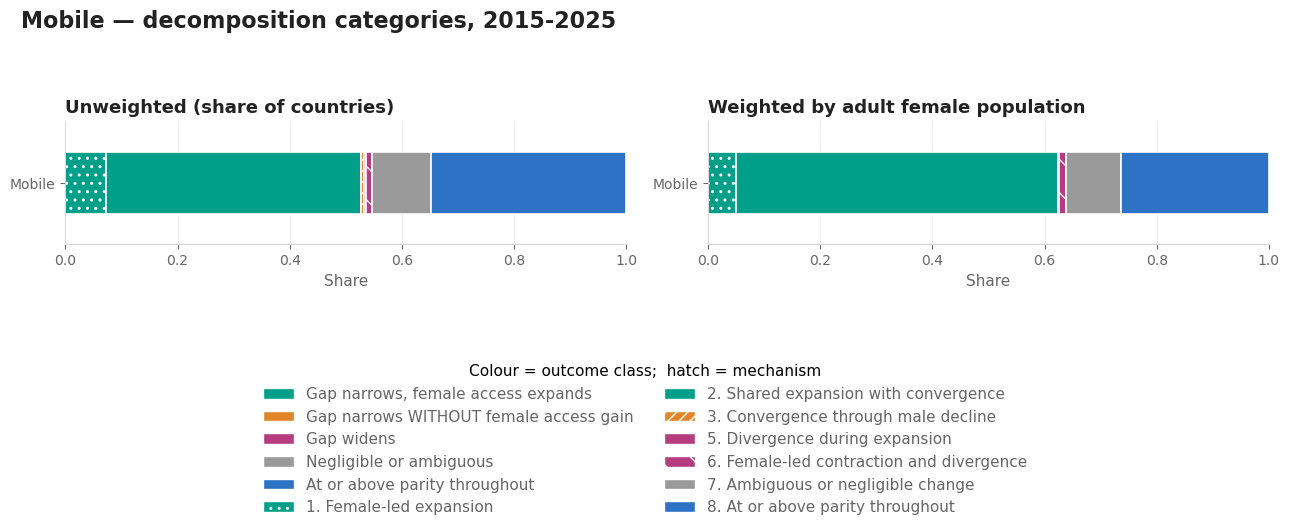

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.0))
block = at(cat_global)

for ax, weighting in zip(axes, ['share_unweighted', 'share_pop_weighted']):
    left = 0.0
    for _, row in block.sort_values('category').iterrows():
        ax.barh(0, row[weighting], left=left, height=0.5,
                edgecolor='white', linewidth=1.2, **cat_style(row['category']))
        left += row[weighting]

    ax.set_yticks([0])
    ax.set_yticklabels([INDICATOR.capitalize()])
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, 0.5)
    title = 'Unweighted (share of countries)' if weighting == 'share_unweighted' \
        else 'Weighted by adult female population'
    tidy(ax, title=title, xlabel='Share')
    ax.grid(axis='y', visible=False)
    ax.grid(axis='x', color=GRID, linewidth=0.5, alpha=0.6)

present = block.loc[block['n_countries'] > 0, 'category']
fig.legend(handles=legend_handles(present), loc='lower center', ncol=2, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.75),
           title='Colour = outcome class;  hatch = mechanism', title_fontsize=STYLE['tick_fs'])
fig.suptitle(f'{INDICATOR.capitalize()} — decomposition categories, {PRIMARY}',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.86])
fig.savefig(FIGDIR / f'global_category_shares_{INDICATOR}.png', dpi=STYLE['dpi'], bbox_inches='tight')
block.round(4)

## Regional stacked bars

  regional_category_shares_mobile.png


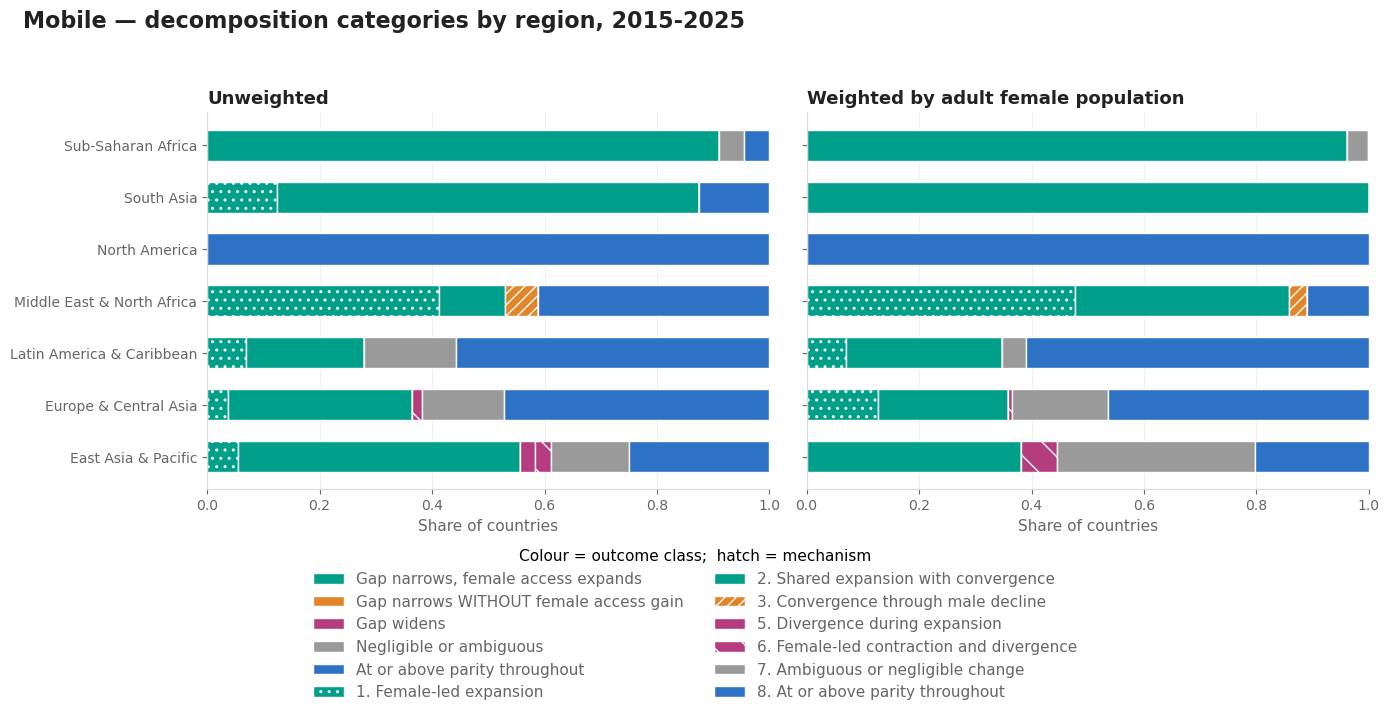

In [5]:
block = at(cat_region)
regions = sorted(block['region'].dropna().unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, weighting in zip(axes, ['share_unweighted', 'share_pop_weighted']):
    left = dict.fromkeys(regions, 0.0)
    for _, row in block.sort_values(['region', 'category']).iterrows():
        region = row['region']
        ax.barh(regions.index(region), row[weighting], left=left[region], height=0.6,
                edgecolor='white', linewidth=1.0, **cat_style(row['category']))
        left[region] += row[weighting]
    ax.set_yticks(range(len(regions)))
    ax.set_yticklabels(regions)
    ax.set_xlim(0, 1)
    title = 'Unweighted' if weighting == 'share_unweighted' else 'Weighted by adult female population'
    tidy(ax, title=title, xlabel='Share of countries')
    ax.grid(axis='y', visible=False)
    ax.grid(axis='x', color=GRID, linewidth=0.5, alpha=0.6)

present = block.loc[block['n_countries'] > 0, 'category']
fig.legend(handles=legend_handles(present), loc='lower center', ncol=2, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.30),
           title='Colour = outcome class;  hatch = mechanism', title_fontsize=STYLE['tick_fs'])
fig.suptitle(f'{INDICATOR.capitalize()} — decomposition categories by region, {PRIMARY}',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIGDIR / f'regional_category_shares_{INDICATOR}.png',
            dpi=STYLE['dpi'], bbox_inches='tight')
print(f'  regional_category_shares_{INDICATOR}.png')

## Female against male growth

Each point is a country over 2015–2025. The diagonal `y = x` is the **convergence/divergence
boundary**: above it female adoption grew proportionally faster and the gap narrowed; below it the
gap widened. The axes are log changes, so the vertical distance from the diagonal *is*
`delta_log_GGI`.

The quadrants matter for interpretation. Only the upper-right quadrant above the diagonal is both a
parity improvement and an access expansion. Points left of the vertical zero line had female
adoption fall; points below the horizontal zero line had male adoption fall.

  named 6 of 207 points — every case in categories [5, 6], plus the 3 largest female components in category 1


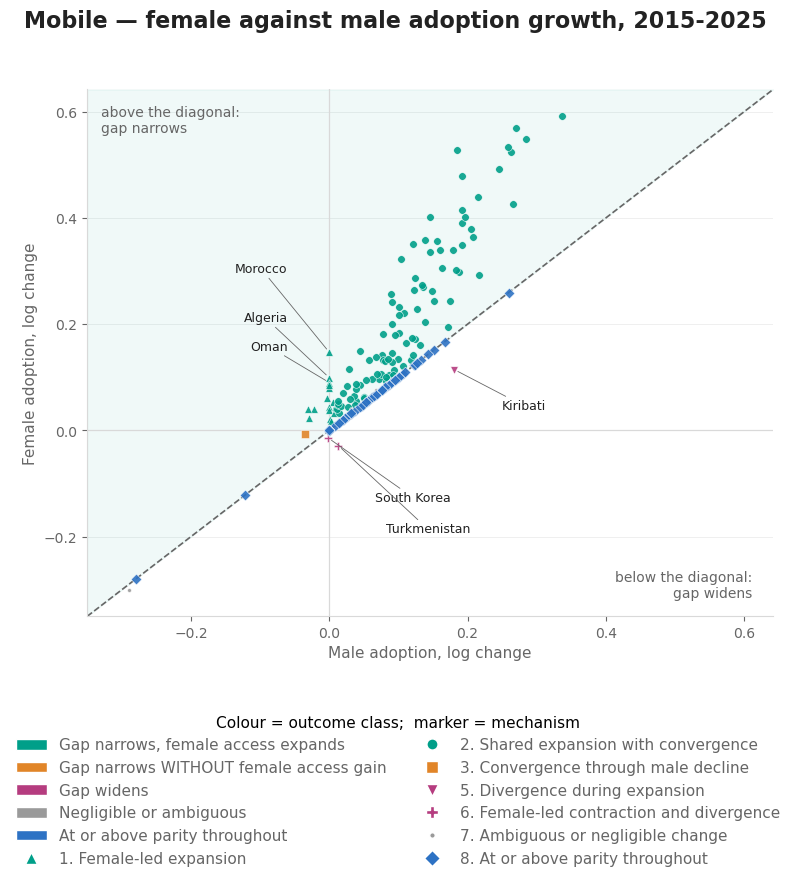

In [6]:
MARKER = {1: '^', 2: 'o', 3: 's', 4: 'X', 5: 'v', 6: 'P', 7: '.', 8: 'D'}

fig, ax = plt.subplots(figsize=(7.8, 6.8))
block = at(country)

# male_component is -(log change in male adoption); plot the raw male log change
x, y = block['male_log_change'], block['female_component']
lim = [min(x.min(), y.min()) - 0.05, max(x.max(), y.max()) + 0.05]

ax.axhline(0, color=GRID, linewidth=0.9)
ax.axvline(0, color=GRID, linewidth=0.9)
ax.plot(lim, lim, ls='--', color=MUTED, linewidth=1.2, zorder=2)
ax.fill_between(lim, lim, [lim[1]] * 2, color=PALETTE[0], alpha=0.06, zorder=1)

for code_ in sorted(block['category'].dropna().unique()):
    pts = block[block['category'] == code_]
    ax.scatter(pts['male_log_change'], pts['female_component'], s=30, alpha=0.9,
               color=CAT_COLOUR[int(code_)], edgecolor='white', linewidth=0.4, zorder=3,
               marker=MARKER[int(code_)])

# ---- name the countries that carry the small categories ------------------------------------------
# 5 and 6 are the divergence cases — the counter-examples a reader goes looking for — and there are
# few enough of them to name every one. 1 is female-led expansion, where naming all of them would be
# unreadable, so only the largest few by female component are labelled. All three are empty for
# internet, which is itself the finding: no internet country diverged over 2015-2025.
NAME_ALL = [5, 6]                 # every case in these categories
NAME_TOP = {1: 3}                 # the n largest female components in these

labelled = pd.concat([block[block['category'].isin(NAME_ALL)]]
                     + [block[block['category'] == c].nlargest(n, 'female_component')
                        for c, n in NAME_TOP.items()])

# Labels go away from the diagonal, so a leader line never crosses it: up-left for the points above
# it, down-right for those below. Within each side they are stacked in the plot's own y-order, which
# keeps the leader lines from crossing each other and separates points only a few thousandths apart
# (Algeria and Oman differ by 0.009 — about ten pixels).
labelled = labelled.assign(above=labelled['female_component'] > labelled['male_log_change'])
for above, side in labelled.groupby('above'):
    dx, step = (-30, 17) if above else (34, -17)
    order = side.sort_values('female_component', ascending=bool(above))
    for rank, (_, row) in enumerate(order.iterrows()):
        ax.annotate(row['country'], xy=(row['male_log_change'], row['female_component']),
                    xytext=(dx, (26 if above else -26) + step * rank),
                    textcoords='offset points',
                    ha='right' if dx < 0 else 'left', va='center',
                    fontsize=STYLE['tick_fs'] - 2, color=INK, zorder=5,
                    arrowprops=dict(arrowstyle='-', linewidth=0.6, color=MUTED,
                                    shrinkA=0, shrinkB=3))

print(f'  named {len(labelled)} of {len(block)} points — every case in categories '
      f'{NAME_ALL}, plus the {list(NAME_TOP.values())[0]} largest female components in '
      f'category {list(NAME_TOP)[0]}')

ax.text(0.02, 0.97, 'above the diagonal:\ngap narrows', transform=ax.transAxes,
        va='top', ha='left', fontsize=STYLE['tick_fs'] - 1, color=MUTED)
ax.text(0.97, 0.03, 'below the diagonal:\ngap widens', transform=ax.transAxes,
        va='bottom', ha='right', fontsize=STYLE['tick_fs'] - 1, color=MUTED)
tidy(ax, xlabel='Male adoption, log change', ylabel='Female adoption, log change')
ax.set_xlim(lim)
ax.set_ylim(lim)

present = sorted(block['category'].dropna().unique())
marker_handles = [plt.Line2D([], [], linestyle='None', markersize=8, marker=MARKER[int(c)],
                             markerfacecolor=CAT_COLOUR[int(c)], markeredgecolor='white',
                             label=f'{int(c)}. {CAT_LABEL[c]}') for c in present]
class_keys = list(dict.fromkeys(CLASS_OF[int(c)] for c in present))
fig.legend(handles=[mpatches.Patch(facecolor=CLASS_COLOUR[k], edgecolor='white', label=CLASS_LABEL[k])
                    for k in class_keys] + marker_handles,
           loc='lower center', ncol=2, frameon=False, fontsize=STYLE['tick_fs'],
           labelcolor=MUTED, bbox_to_anchor=(0.5, -0.30),
           title='Colour = outcome class;  marker = mechanism', title_fontsize=STYLE['tick_fs'])
fig.suptitle(f'{INDICATOR.capitalize()} — female against male adoption growth, {PRIMARY}',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(FIGDIR / f'female_vs_male_growth_{INDICATOR}.png', dpi=STYLE['dpi'], bbox_inches='tight')

## Map of decomposition categories

  category_map_mobile.png  (grey = excluded, no log change defined)


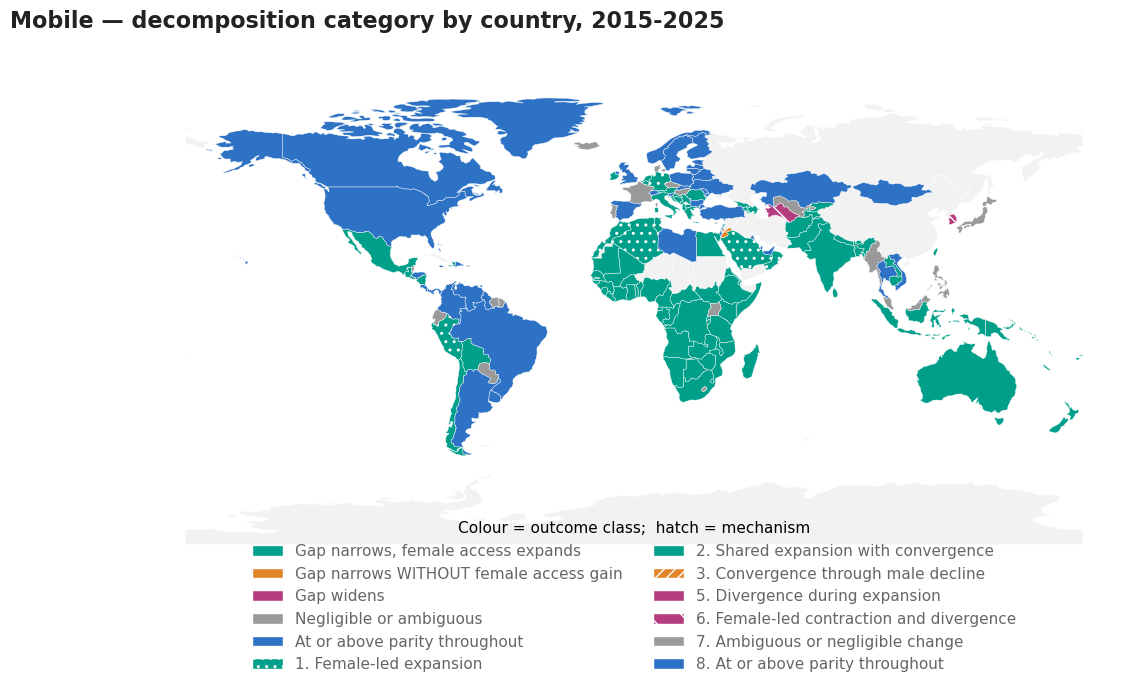

In [7]:
world = utils.load_world()
fig, ax = plt.subplots(figsize=(13, 6.5))

block = at(country)
merged = world.merge(block[['gid_0', 'category']], left_on='iso_a3', right_on='gid_0', how='left')

world.plot(ax=ax, color='#f2f2f2', edgecolor='white', linewidth=0.3)
for code_ in sorted(block['category'].dropna().unique()):
    sub = merged[merged['category'] == code_]
    if len(sub):
        sub.plot(ax=ax, edgecolor='white', linewidth=0.3, **cat_style(code_))
ax.axis('off')

fig.legend(handles=legend_handles(block['category'].dropna()), loc='lower center', ncol=2,
           frameon=False, fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.06),
           title='Colour = outcome class;  hatch = mechanism', title_fontsize=STYLE['tick_fs'])
fig.suptitle(f'{INDICATOR.capitalize()} — decomposition category by country, {PRIMARY}',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0.10, 1, 0.96])
fig.savefig(FIGDIR / f'category_map_{INDICATOR}.png', dpi=STYLE['dpi'], bbox_inches='tight')
print(f'  category_map_{INDICATOR}.png  (grey = excluded, no log change defined)')

## Largest parity changes

Twenty largest improvements and deteriorations for the displayed indicator, showing which component drives each.
"Improvement" here refers to **parity** only; the access columns say whether women actually gained.

In [8]:
ext = sel(extremes)
display(ext[ext['rank_type'] == 'largest parity improvement'].head(20).round(4))
ext[ext['rank_type'] == 'largest parity deterioration'].head(20).round(4)

,indicator,gid_0,country,region,delta_log_ggi,female_component,male_component,category_label,parity_direction,female_access_direction,parity_improved_without_access_gain,rank_type
40,mobile,PAK,Pakistan,South Asia,0.3424,0.5275,-0.1851,Shared expansion with convergence,improving,expanding,False,largest parity improvement
41,mobile,BEN,Benin,Sub-Saharan Africa,0.2993,0.5695,-0.2702,Shared expansion with convergence,improving,expanding,False,largest parity improvement
42,mobile,COD,DR Congo,Sub-Saharan Africa,0.2882,0.4795,-0.1913,Shared expansion with convergence,improving,expanding,False,largest parity improvement
43,mobile,SSD,South Sudan,Sub-Saharan Africa,0.2749,0.5337,-0.2588,Shared expansion with convergence,improving,expanding,False,largest parity improvement
44,mobile,MWI,Malawi,Sub-Saharan Africa,0.2643,0.5481,-0.2837,Shared expansion with convergence,improving,expanding,False,largest parity improvement
45,mobile,BGD,Bangladesh,South Asia,0.2607,0.5230,-0.2622,Shared expansion with convergence,improving,expanding,False,largest parity improvement
46,mobile,TGO,Togo,Sub-Saharan Africa,0.2559,0.4010,-0.1450,Shared expansion with convergence,improving,expanding,False,largest parity improvement
47,mobile,BFA,Burkina Faso,Sub-Saharan Africa,0.2558,0.5915,-0.3357,Shared expansion with convergence,improving,expanding,False,largest parity improvement
48,mobile,MRT,Mauritania,Sub-Saharan Africa,0.2465,0.4916,-0.2452,Shared expansion with convergence,improving,expanding,False,largest parity improvement
49,mobile,LBR,Liberia,Sub-Saharan Africa,0.2290,0.3503,-0.1213,Shared expansion with convergence,improving,expanding,False,largest parity improvement


,indicator,gid_0,country,region,delta_log_ggi,female_component,male_component,category_label,parity_direction,female_access_direction,parity_improved_without_access_gain,rank_type
60,mobile,KIR,Kiribati,East Asia & Pacific,-0.0660,0.1145,-0.1805,Divergence during expansion,worsening,expanding,False,largest parity deterioration
61,mobile,TKM,Turkmenistan,Europe & Central Asia,-0.0419,-0.0288,-0.0131,Female-led contraction and divergence,worsening,contracting,False,largest parity deterioration
62,mobile,KOR,South Korea,East Asia & Pacific,-0.0124,-0.0142,0.0018,Female-led contraction and divergence,worsening,contracting,False,largest parity deterioration
63,mobile,MMR,Myanmar,East Asia & Pacific,-0.0099,-0.3000,0.2901,Ambiguous or negligible change,stable,contracting,False,largest parity deterioration
64,mobile,ABW,Aruba,Latin America & Caribbean,0.0000,0.0367,-0.0367,At or above parity throughout,stable,expanding,False,largest parity deterioration
65,mobile,LIE,Liechtenstein,Europe & Central Asia,0.0000,0.0000,-0.0000,At or above parity throughout,stable,stable,False,largest parity deterioration
66,mobile,LTU,Lithuania,Europe & Central Asia,0.0000,0.0987,-0.0987,At or above parity throughout,stable,expanding,False,largest parity deterioration
67,mobile,LUX,Luxembourg,Europe & Central Asia,0.0000,0.0000,-0.0000,At or above parity throughout,stable,stable,False,largest parity deterioration
68,mobile,LVA,Latvia,Europe & Central Asia,0.0000,0.0858,-0.0858,At or above parity throughout,stable,expanding,False,largest parity deterioration
69,mobile,MCO,Monaco,Europe & Central Asia,0.0000,0.0000,-0.0000,At or above parity throughout,stable,stable,False,largest parity deterioration


## Regional aggregate decomposition

Regional levels are the population-weighted means of country levels, each sex on its **own**
denominator: regional female level weights by adult female population, regional male level by adult
male population. Weights are fixed at 2015 — the UN file stops at 2024 so 2025 has no population of
its own, and fixed weights keep the identity exact by preventing population composition change from
entering a decomposition that only claims to measure adoption change.

,indicator,interval,region,n_countries,female_level_t0,female_level_t1,male_level_t0,male_level_t1,ggi_t0,ggi_t1,female_component,male_component,delta_log_ggi,parity_direction,female_access_direction
25,mobile,2015-2025,North America,3,0.9241,0.9993,0.9242,0.9993,1.0000,1.0000,0.0782,-0.0782,0.0000,stable,expanding
23,mobile,2015-2025,Latin America & Caribbean,43,0.8234,0.8847,0.8354,0.8861,0.9856,0.9985,0.0718,-0.0589,0.0130,improving,expanding
22,mobile,2015-2025,Europe & Central Asia,55,0.8917,0.9468,0.9149,0.9561,0.9746,0.9903,0.0600,-0.0441,0.0159,improving,expanding
21,mobile,2015-2025,East Asia & Pacific,36,0.8380,0.8950,0.8796,0.9244,0.9527,0.9683,0.0658,-0.0496,0.0162,improving,expanding
24,mobile,2015-2025,Middle East & North Africa,17,0.8711,0.9646,0.9828,0.9945,0.8863,0.9698,0.1020,-0.0119,0.0901,improving,expanding
27,mobile,2015-2025,Sub-Saharan Africa,45,0.5188,0.6941,0.6933,0.7998,0.7484,0.8679,0.2911,-0.1429,0.1481,improving,expanding
26,mobile,2015-2025,South Asia,8,0.5608,0.8497,0.8180,0.9959,0.6856,0.8532,0.4154,-0.1968,0.2187,improving,expanding


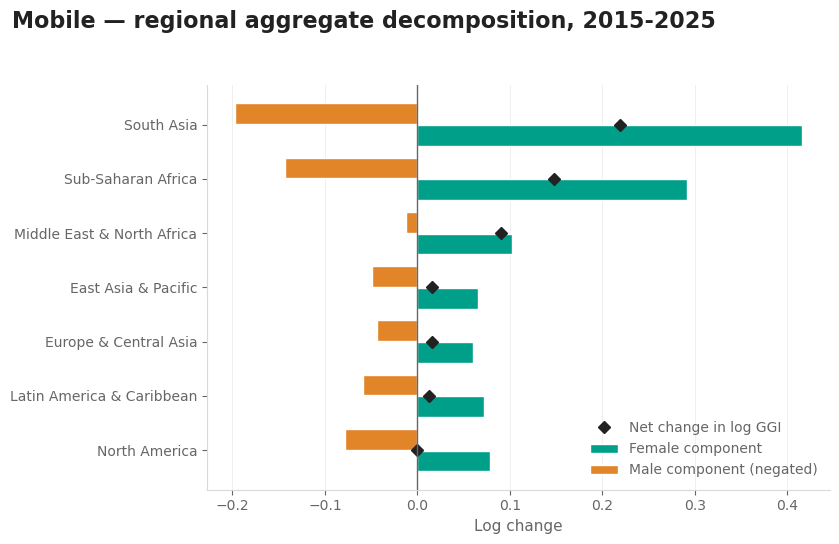

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
block = at(regional).sort_values('delta_log_ggi')
y = np.arange(len(block))

ax.barh(y - 0.2, block['female_component'], height=0.38, color=PALETTE[0],
        edgecolor='white', label='Female component')
ax.barh(y + 0.2, block['male_component'], height=0.38, color=PALETTE[1],
        edgecolor='white', label='Male component (negated)')
ax.plot(block['delta_log_ggi'], y, 'D', color=INK, markersize=6, label='Net change in log GGI')
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(block['region'])
tidy(ax, xlabel='Log change')
ax.grid(axis='y', visible=False)
ax.grid(axis='x', color=GRID, linewidth=0.5, alpha=0.6)
ax.legend(frameon=False, fontsize=STYLE['tick_fs'] - 1, loc='lower right', labelcolor=MUTED)

fig.suptitle(f'{INDICATOR.capitalize()} — regional aggregate decomposition, {PRIMARY}',
             fontsize=STYLE['title_fs'],
             color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(FIGDIR / f'regional_aggregate_decomposition_{INDICATOR}.png',
            dpi=STYLE['dpi'], bbox_inches='tight')
block.round(4)

## Generated summary

**This is the one section that ignores `INDICATOR`.** It writes
`doc/06_coherent_ggi_decomposition_report.md`, a repo artefact referenced from the README, so it covers both
indicators whichever one the figures above are showing. Halving the document to match the display
would be a regression, not a filter.

In [10]:
def summary_text():
    """compose the summary from the tables, keeping parity and access strictly separate"""
    lines = [
        f'Everything below runs on the filtered series: a country-year whose coherent gender gap '
        f'index differs from the directly predicted one by more than {CUT} is withheld for that '
        f'indicator before the decomposition, because a disagreement about the ratio is a '
        f'disagreement about the levels the decomposition attributes change to. The filter costs '
        f"{100 - disc_filter.set_index('indicator').loc['internet', 'kept_pct']:.0f}% of internet "
        f"country-years and {100 - disc_filter.set_index('indicator').loc['mobile', 'kept_pct']:.0f}% "
        f'of mobile ones; because an interval needs a level at both endpoints, the country loss is '
        f'larger still and is stated per indicator below.',

        'Because the coherent gender gap index is a ratio of predicted female to predicted male '
        'adoption, its log change decomposes exactly into a female and a male term. The identity '
        f"holds to {identity['max_abs_residual'].iloc[0]:.0e} across "
        f"{int(identity['n_rows'].iloc[0])} country-periods. This separation matters because a "
        'narrowing gap can reflect women gaining access, men losing it, or both sexes losing access '
        'with men losing more; only the first is an expansion of digital access for women.']

    for ind in params.COHERENT_GGI['indicators']:
        exc = exclusions[(exclusions['indicator'] == ind) & (exclusions['interval'] == PRIMARY)].iloc[0]
        g = cat_global[(cat_global['indicator'] == ind) & (cat_global['interval'] == PRIMARY)]
        g = g.set_index('category')
        shared = g.loc[2]
        no_access = g.loc[list(NO_ACCESS_GAIN)]
        diverge = g.loc[5]

        # The exclusion sentence has to name the reason that actually dominates. Since D43 that is
        # the discrepancy filter, not the zero floor.
        #
        # Do NOT add the two zero counts: `n_excluded_zero_female` and `n_excluded_zero_male` are
        # per-endpoint flags on the same rows, so a country with both levels at zero (Niger 2015,
        # the only one) is counted twice and the reasons no longer sum to `n_excluded`. Take the
        # blanked count from `n_excluded_missing`, which is a row count, and leave the rest as
        # zeros — that partitions the exclusions exactly, because `decompose` drops a row for a
        # missing level or a non-positive one and nothing else.
        blanked = int(exc['n_excluded_missing'])
        zero = int(exc['n_excluded']) - blanked
        reason = []
        if blanked:
            reason.append(f"{blanked} because the coherent and the directly predicted index "
                          f"disagree by more than {CUT} at one or both endpoints, so the "
                          'country-year is withheld')
        if zero:
            reason.append(f"{zero} because a predicted level is exactly zero at an endpoint")

        lines.append(
            f"For {ind} over 2015-2025, {int(exc['n_included'])} of "
            f"{int(exc['n_countries_available'])} countries have a defined log change; "
            f"{int(exc['n_excluded'])} are excluded - {'; '.join(reason)}. "
            f"Of those included, {int(shared['n_countries'])} "
            f"({shared['share_unweighted']:.1%} of countries, {shared['share_pop_weighted']:.1%} of "
            'adult women) fall into shared expansion with convergence: both sexes gained access and '
            'women gained proportionally faster, so parity improved alongside access expansion. A '
            f"further {int(diverge['n_countries'])} ({diverge['share_unweighted']:.1%}) show "
            'divergence during expansion, where access grew but men gained faster and the gap widened.')

        at_parity = g.loc[8] if 8 in g.index else None
        if at_parity is not None and int(at_parity['n_countries']):
            lines.append(
                f"A further {int(at_parity['n_countries'])} {ind} countries "
                f"({at_parity['share_unweighted']:.1%} of countries, "
                f"{at_parity['share_pop_weighted']:.1%} of adult women) were at or above parity at "
                'both endpoints. They are reported as a standing state rather than as change: there '
                'was no gap against women to close. They are retained in the denominator, because '
                'excluding them would remove countries non-randomly by region and income level.')

        n_no_access = int(no_access['n_countries'].sum())
        if n_no_access:
            names = country[(country['interval'] == PRIMARY) & (country['indicator'] == ind)
                            & country['parity_improved_without_access_gain']]['country'].tolist()
            lines.append(
                f"In {n_no_access} {ind} case(s) - {', '.join(names)} - the gap narrowed without "
                'women gaining access: either male adoption fell while female adoption was flat, or '
                'both fell and male adoption fell faster. These are improvements in parity, not in '
                'digital access, and should not be reported as the latter.')

    # regional aggregate: state parity and access separately
    for ind in params.COHERENT_GGI['indicators']:
        r = regional[(regional['interval'] == PRIMARY) & (regional['indicator'] == ind)]
        improving = r[r['parity_direction'] == 'improving']
        expanding = r[r['female_access_direction'] == 'expanding']
        biggest = r.loc[r['delta_log_ggi'].idxmax()]
        lines.append(
            f"At regional level for {ind}, {len(improving)} of {len(r)} regions show improving "
            f"parity and {len(expanding)} of {len(r)} show expanding female access. The largest "
            f"parity gain is {biggest['region']} ({biggest['delta_log_ggi']:+.3f} log points), "
            f"where the female component contributes {biggest['female_component']:+.3f} and the "
            f"male component {biggest['male_component']:+.3f} - that is, female adoption rose "
            f"faster than male adoption, both having risen.")

    lines.append(
        'Two caveats bound the country-level results. The excluded countries are not a random '
        'subset. Most of them are now withheld by the discrepancy filter rather than by the zero '
        'floor of the level model, but the two sets overlap almost completely - the countries whose '
        'predicted female level sits on that floor are also the ones where the coherent and the '
        'directly predicted index disagree most - so the countries that drop out remain among the '
        'most gender-unequal in the sample and the reported distribution understates the tail. And '
        'an epsilon substitution was tested but not adopted, because it changes no existing '
        'estimate and only manufactures a log change where the underlying level is exactly zero.')

    return '\n\n'.join(lines)


text = summary_text()
out = params.DOC / '06_coherent_ggi_decomposition_report.md'
out.write_text('# Decomposition of coherent-GGI change\n\n'
               '<!-- generated by src/analysis_notebooks/06_coherent_ggi_decomposition.ipynb '
               '— do not edit by hand -->\n\n'
               + text + '\n')
print(f'written to {out.relative_to(params.ROOT)}\n')
print(text)

written to doc/decomposition_coherent_ggi.md

Everything below runs on the filtered series: a country-year whose coherent gender gap index differs from the directly predicted one by more than 0.07 is withheld for that indicator before the decomposition, because a disagreement about the ratio is a disagreement about the levels the decomposition attributes change to. The filter costs 21% of internet country-years and 1% of mobile ones; because an interval needs a level at both endpoints, the country loss is larger still and is stated per indicator below.

Because the coherent gender gap index is a ratio of predicted female to predicted male adoption, its log change decomposes exactly into a female and a male term. The identity holds to 4e-16 across 4752 country-periods. This separation matters because a narrowing gap can reflect women gaining access, men losing it, or both sexes losing access with men losing more; only the first is an expansion of digital access for women.

For internet 

## Notes

- `INDICATOR` at the top of the setup cell chooses what is displayed. Figures carry it in their
  filename (`..._{INDICATOR}.png`), so switching and rerunning accumulates both sets rather than
  overwriting one with the other. They write to `outputs/fig/06_coherent_ggi_decomposition/`; every
  table is in `outputs/tables/06_coherent_ggi_decomposition/` under the `ggi_decomposition_` prefix,
  and each still holds **both** indicators — only the display is filtered.
- Legends are built from the categories actually present in the panel, so an indicator that occupies
  only part of the typology no longer advertises the empty classes. Internet occupies three of the
  eight; mobile occupies seven.
- **Parity and access are reported separately throughout.** `parity_direction` and
  `female_access_direction` are distinct columns on every country-period row, and categories 3 and 4
  carry `parity_improved_without_access_gain = True`. They are hatched in every chart so the
  distinction does not rest on recalling a colour.
- Weights are fixed at the 2015 adult population, by sex. See the regional section for why.